# Tugas Praktikum - JST untuk Klasifikasi Angka Tulisan Tangan (MNIST)

**Nama:** Agus
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js13-artificial-neural-network-ann-dan-evaluasi-classifier/tugas-praktikum)

Langkah modul: load MNIST dari Keras, bangun model dengan 2 hidden layer, latih, lalu evaluasi akurasi. Bagian yang dikosongkan modul
(model, kompilasi, pelatihan) diisi sebagai berikut: Flatten → Dense 128 ReLU → Dense 64 ReLU → Dense 10 softmax, Adam,
categorical cross-entropy, 10 epoch, batch 32, dan 10% data latih sebagai validasi. Setelah itu dijalankan eksperimen parameter yang diminta modul.

In [1]:
import sys
import numpy as np
import tensorflow as tf
tf.keras.utils.set_random_seed(42)
print("Kernel:", sys.executable)
print("TensorFlow:", tf.__version__)

Kernel: /Users/jergal/College/machine-learning-smt-5/.venv/bin/python
TensorFlow: 2.21.0


In [2]:
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Input
from tensorflow.keras.utils import to_categorical

# 1. Load dataset MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()
y_test_int = y_test.copy()

# Normalisasi data (0-255 → 0-1)
X_train = X_train / 255.0
X_test = X_test / 255.0

# One-hot encoding label
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)
print(X_train.shape, X_test.shape)

       0/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   32768/11490434 ━━━━━━━━━━━━━━━━━━━━ 17s 2us/step

   49152/11490434 ━━━━━━━━━━━━━━━━━━━━ 40s 4us/step

   81920/11490434 ━━━━━━━━━━━━━━━━━━━━ 48s 4us/step

  172032/11490434 ━━━━━━━━━━━━━━━━━━━━ 26s 2us/step

  327680/11490434 ━━━━━━━━━━━━━━━━━━━━ 15s 1us/step

... (14 outputs left out)

10092544/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

10747904/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


(60000, 28, 28) (10000, 28, 28)


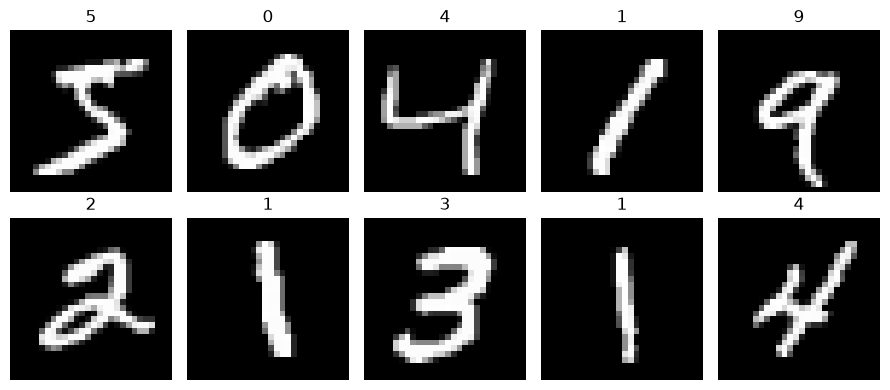

In [3]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1); plt.imshow(X_train[i], cmap='gray'); plt.axis('off'); plt.title(int(y_train[i].argmax()))
plt.tight_layout(); plt.show()

In [4]:
# 2. Bangun model JST
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),                        # Ubah gambar 28x28 menjadi vektor
    Dense(128, activation='relu'),    # Hidden layer 1
    Dense(64, activation='relu'),     # Hidden layer 2
    Dense(10, activation='softmax')   # Output layer (10 kelas)
])

# 3. Kompilasi model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

# 4. Latih model
history = model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.1, verbose=2)

# 5. Evaluasi model
loss, acc = model.evaluate(X_test, y_test)
print(f"Akurasi pada data uji: {acc:.4f}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


... (19 outputs left out)

  1/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 1.0000 - loss: 0.0071

185/313 ━━━━━━━━━━━━━━━━━━━━ 0s 272us/step - accuracy: 0.9642 - loss: 0.1499

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 284us/step - accuracy: 0.9706 - loss: 0.1223


Akurasi pada data uji: 0.9706


              precision    recall  f1-score   support

           0     0.9887    0.9786    0.9836       980
           1     0.9851    0.9912    0.9881      1135
           2     0.9869    0.9457    0.9659      1032
           3     0.9309    0.9871    0.9582      1010
           4     0.9822    0.9542    0.9680       982
           5     0.9771    0.9563    0.9666       892
           6     0.9649    0.9760    0.9704       958
           7     0.9755    0.9669    0.9712      1028
           8     0.9567    0.9754    0.9659       974
           9     0.9608    0.9713    0.9660      1009

    accuracy                         0.9706     10000
   macro avg     0.9709    0.9703    0.9704     10000
weighted avg     0.9710    0.9706    0.9706     10000



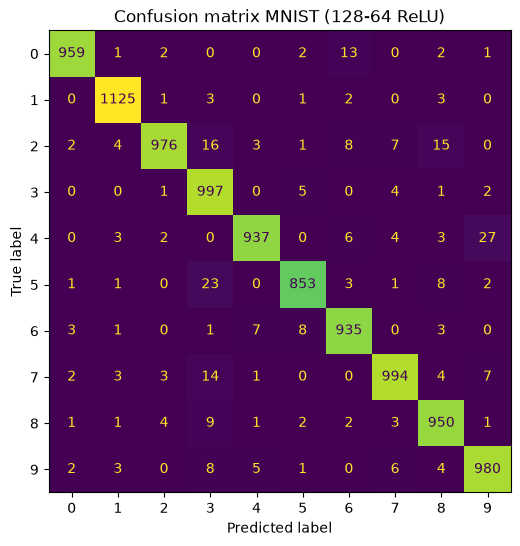

In [5]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
y_pred = model.predict(X_test, verbose=0).argmax(1)
print(classification_report(y_test_int, y_pred, digits=4))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test_int, y_pred, ax=ax, colorbar=False)
plt.title('Confusion matrix MNIST (128-64 ReLU)'); plt.show()

## Coba dengan beberapa parameter lain

* Ubah jumlah neuron di hidden layer (256 dan 128).
* Tambahkan satu hidden layer lagi.
* Bandingkan akurasi dan waktu pelatihan.
* Eksperimen dengan fungsi aktivasi **Sigmoid** vs **ReLU**.

Seed, data, optimizer, epoch, dan batch dibuat sama untuk semua model. Waktu pelatihan diukur dengan `time.perf_counter()` di CPU komputer ini.

In [6]:
import time, pandas as pd

def build(hidden, activation):
    return Sequential([Input(shape=(28, 28)), Flatten()]
                      + [Dense(h, activation=activation) for h in hidden]
                      + [Dense(10, activation='softmax')])

experiments = {
    'A. 128-64 ReLU (dasar)': ((128, 64), 'relu'),
    'B. 256-128 ReLU': ((256, 128), 'relu'),
    'C. 256-128-64 ReLU (+1 layer)': ((256, 128, 64), 'relu'),
    'D. 128-64 Sigmoid': ((128, 64), 'sigmoid'),
    'E. 256-128 Sigmoid': ((256, 128), 'sigmoid'),
    'F. 256-128-64 Sigmoid (+1 layer)': ((256, 128, 64), 'sigmoid'),
}
rows, hists = [], {}
for name, (hidden, act) in experiments.items():
    tf.keras.utils.set_random_seed(42)
    m = build(hidden, act)
    m.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    t0 = time.perf_counter()
    h = m.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.1, verbose=0)
    dur = time.perf_counter() - t0
    loss, acc = m.evaluate(X_test, y_test, verbose=0)
    hists[name] = h.history
    rows.append({'model': name, 'parameter': m.count_params(), 'train_acc': h.history['accuracy'][-1],
                 'val_acc': h.history['val_accuracy'][-1], 'test_acc': acc, 'test_loss': loss, 'waktu_latih_s': dur})
results = pd.DataFrame(rows).set_index('model')
results.round(4)

,parameter,train_acc,val_acc,test_acc,test_loss,waktu_latih_s
model,,,,,,
A. 128-64 ReLU (dasar),109386,0.9935,0.9745,0.9706,0.1223,9.2147
B. 256-128 ReLU,235146,0.9947,0.9803,0.9772,0.1017,12.8417
C. 256-128-64 ReLU (+1 layer),242762,0.9934,0.9770,0.9770,0.1180,13.2757
D. 128-64 Sigmoid,109386,0.9952,0.9790,0.9762,0.0796,9.2467
E. 256-128 Sigmoid,235146,0.9976,0.9742,0.9726,0.1014,13.0867
F. 256-128-64 Sigmoid (+1 layer),242762,0.9955,0.9728,0.9688,0.1258,13.6839


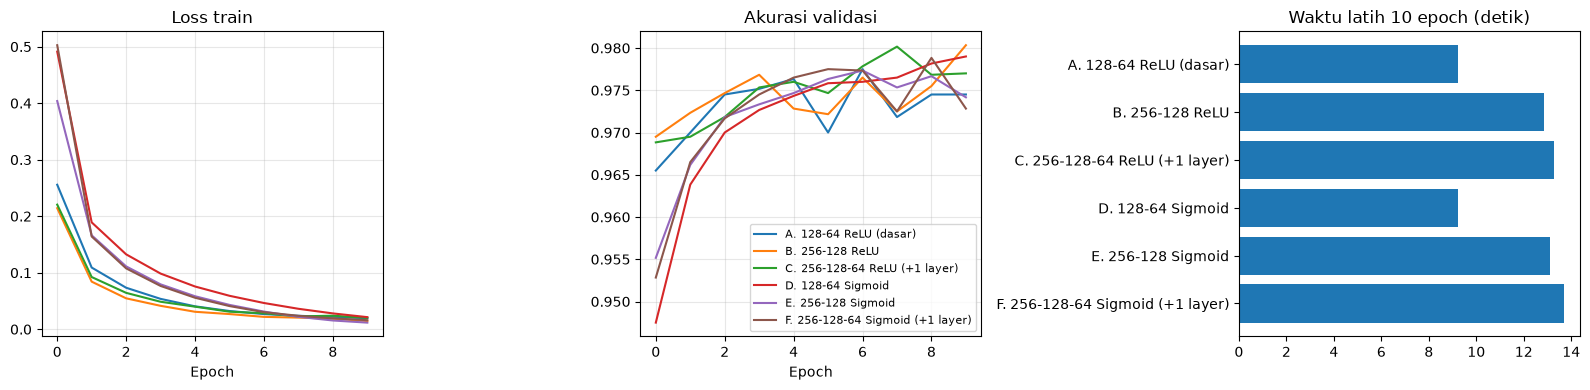

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for name, hh in hists.items():
    ax[0].plot(hh['loss'], label=name); ax[1].plot(hh['val_accuracy'], label=name)
ax[0].set_title('Loss train'); ax[1].set_title('Akurasi validasi')
for a in ax[:2]: a.set_xlabel('Epoch'); a.grid(alpha=.3)
ax[1].legend(fontsize=8)
ax[2].barh(results.index, results['waktu_latih_s']); ax[2].set_title('Waktu latih 10 epoch (detik)'); ax[2].invert_yaxis()
plt.tight_layout(); plt.show()

## Analisis

**Model dasar 128-64 ReLU:** akurasi test **97,06%** dalam 9,2 detik (10 epoch, CPU Apple M4). Kelas yang paling sulit adalah angka 3 (presisi terendah, 0,931) dan angka 2 (recall terendah, 0,946). Rinciannya terlihat pada confusion matrix.

| Model | Parameter | Akurasi train | Akurasi test | Loss test | Waktu latih (s) |
| --- | --- | --- | --- | --- | --- |
| A. 128-64 ReLU (dasar) | 109.386 | 99,35% | 97,06% | 0,122 | 9,2 |
| B. 256-128 ReLU | 235.146 | 99,47% | **97,72%** | 0,102 | 12,8 |
| C. 256-128-64 ReLU (+1 layer) | 242.762 | 99,34% | 97,70% | 0,118 | 13,3 |
| D. 128-64 Sigmoid | 109.386 | 99,52% | 97,62% | **0,080** | 9,2 |
| E. 256-128 Sigmoid | 235.146 | 99,76% | 97,26% | 0,101 | 13,1 |
| F. 256-128-64 Sigmoid (+1 layer) | 242.762 | 99,55% | 96,88% | 0,126 | 13,7 |

1. **Jumlah neuron 256-128.** Akurasi naik 0,66 poin (97,06 → 97,72%), dengan jumlah parameter 2,1 kali lipat dan waktu latih 39% lebih lama. Kapasitas tambahan membantu karena input berdimensi 784.
2. **Tambahan satu hidden layer.** Pada ReLU tidak ada perbaikan (97,70% vs 97,72%), sedangkan pada sigmoid akurasi turun (97,26 → 96,88%). Jaringan lebih dalam tidak otomatis lebih baik pada MLP. Sigmoid yang ditumpuk lebih dalam memperparah gradien yang mengecil (Glorot & Bengio, 2010).
3. **Waktu pelatihan.** Waktu naik hampir linier terhadap jumlah parameter (9 s → 13 s). Fungsi aktivasi tidak berpengaruh berarti pada waktu.
4. **Sigmoid vs ReLU.** Pada jaringan 2 layer dengan optimizer Adam dan input ternormalisasi 0-1, sigmoid 128-64 justru sedikit lebih baik (97,62%) dengan loss test terendah. Keunggulan ReLU (Glorot dkk., 2011) paling terasa pada jaringan dalam. Pada jaringan dangkal, perbedaannya kurang dari 1 poin dan dapat berbalik antar-seed.
5. **Overfitting.** Akurasi train semua model mencapai 99,3-99,8%, sedangkan test 96,9-97,7%. Loss test model ReLU lebih tinggi karena prediksinya terlalu yakin pada sampel yang salah. Regularisasi seperti Dropout (Srivastava dkk., 2014) atau early stopping akan memperkecil celah ini.

**Perbandingan dengan literatur:** LeCun dkk. (1998) melaporkan error MNIST 4,7% untuk JST 2 layer 300 neuron dan 2,95% untuk JST 3 layer 500-150 (tanpa distorsi data). Simard dkk. (2003) mencapai 1,6% dengan MLP 800 neuron dan *cross-entropy*. Error model di sini (2,3-3,1%) berada di rentang yang sama dengan MLP pada literatur. Untuk menembus di bawah 1%, diperlukan CNN, yang dibahas pada JS14. Selisih antar-konfigurasi berasal dari satu seed, sehingga perbedaan kurang dari 0,5 poin belum dapat dianggap signifikan.

## Rujukan

1. LeCun, Y., Bottou, L., Bengio, Y., & Haffner, P. (1998). Gradient-based learning applied to document recognition. *Proceedings of the IEEE*, 86(11), 2278-2324. https://doi.org/10.1109/5.726791
2. Simard, P. Y., Steinkraus, D., & Platt, J. C. (2003). Best practices for convolutional neural networks applied to visual document analysis. *Proceedings of the 7th International Conference on Document Analysis and Recognition (ICDAR)*, 958-963. https://doi.org/10.1109/ICDAR.2003.1227801
3. Glorot, X., Bordes, A., & Bengio, Y. (2011). Deep sparse rectifier neural networks. *Proceedings of AISTATS*, PMLR 15, 315-323.
4. Glorot, X., & Bengio, Y. (2010). Understanding the difficulty of training deep feedforward neural networks. *Proceedings of AISTATS*, PMLR 9, 249-256.
5. Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *Journal of Machine Learning Research*, 15(56), 1929-1958.